# MPHO HADBEBE - CSC2042S ASSIGNMENT 2
 ### Logisitc Regression
 ### News Topic Classification

## bigger picture
### Raw news → clean/tokenise → BoW/TF-IDF vectors → multinomial logistic regression → train → validation tuning → choose best models → test → weight analysis → isiXhosa sampling → bilingual models → final evaluation/report.

##1. Data Proccessing

In [103]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

### 1.1 Load the datasets

In [1]:
import pandas as pd
import re

In [2]:
# The assignment uses three languages:
# English (eng), isiXhosa (xho), and chiShona (sna).
# Each language has predefined train, development, and test splits.

# English
eng_train = pd.read_csv(
    "../news-dataset/news-dataset/eng/train.tsv",
    sep="\t"
)

eng_dev = pd.read_csv(
    "../news-dataset/news-dataset/eng/dev.tsv",
    sep="\t"
)

eng_test = pd.read_csv(
    "../news-dataset/news-dataset/eng/test.tsv",
    sep="\t"
)

# isiXhosa
xho_train = pd.read_csv(
    "../news-dataset/news-dataset/xho/train.tsv",
    sep="\t"
)

xho_dev = pd.read_csv(
    "../news-dataset/news-dataset/xho/dev.tsv",
    sep="\t"
)

xho_test = pd.read_csv(
    "../news-dataset/news-dataset/xho/test.tsv",
    sep="\t"
)

# chiShona
sna_train = pd.read_csv(
    "../news-dataset/news-dataset/sna/train.tsv",
    sep="\t"
)

sna_dev = pd.read_csv(
    "../news-dataset/news-dataset/sna/dev.tsv",
    sep="\t"
)

sna_test = pd.read_csv(
    "../news-dataset/news-dataset/sna/test.tsv",
    sep="\t"
)

### 1.2 Inspect the dataset structure

In [8]:
print("English columns:")
print(eng_train.columns)

print("\nisiXhosa columns:")
print(xho_train.columns)

print("\nchiShona columns:")
print(sna_train.columns)

English columns:
Index(['category', 'headline', 'text', 'url'], dtype='str')

isiXhosa columns:
Index(['category', 'headline', 'text', 'url'], dtype='str')

chiShona columns:
Index(['category', 'headline', 'text', 'url'], dtype='str')


### 1.3 Count examples in each split


In [3]:
split_counts = pd.DataFrame({
    "Language": ["English", "isiXhosa", "chiShona"],
    "Train": [
        len(eng_train),
        len(xho_train),
        len(sna_train)
    ],
    "Dev": [
        len(eng_dev),
        len(xho_dev),
        len(sna_dev)
    ],
    "Test": [
        len(eng_test),
        len(xho_test),
        len(sna_test)
    ]
})

split_counts

,Language,Train,Dev,Test
0,English,3309,472,948
1,isiXhosa,1032,147,297
2,chiShona,1288,185,369


### 1.4 Check for missing values


In [4]:
for df in [
    eng_train, eng_dev, eng_test,
    xho_train, xho_dev, xho_test,
    sna_train, sna_dev, sna_test
]:
    df["full_text"] = (
        df["headline"].fillna("") + " " +
        df["text"].fillna("")
    ).str.strip()

In [5]:
print("Missing full_text values")

print("English train:", eng_train["full_text"].isna().sum())
print("English dev:", eng_dev["full_text"].isna().sum())
print("English test:", eng_test["full_text"].isna().sum())

print("\nisiXhosa train:", xho_train["full_text"].isna().sum())
print("isiXhosa dev:", xho_dev["full_text"].isna().sum())
print("isiXhosa test:", xho_test["full_text"].isna().sum())

print("\nchiShona train:", sna_train["full_text"].isna().sum())
print("chiShona dev:", sna_dev["full_text"].isna().sum())
print("chiShona test:", sna_test["full_text"].isna().sum())

Missing full_text values
English train: 0
English dev: 0
English test: 0

isiXhosa train: 0
isiXhosa dev: 0
isiXhosa test: 0

chiShona train: 0
chiShona dev: 0
chiShona test: 0


### 1.5 Basic text cleaning

In [6]:
def clean_text(text):
    # Convert all text to lowercase.
    # This prevents words such as "Sport" and "sport" from becoming
    # two separate vocabulary entries.
    text = text.lower()

    # Replace punctuation with spaces.
    # Punctuation is not being used as a feature in this model, so
    # removing it keeps the vocabulary focused on words.
    text = re.sub(r"[^\w\s]", " ", text)

    # Removing punctuation can leave multiple spaces between words.
    # These are replaced with a single space for consistent text.
    text = re.sub(r"\s+", " ", text).strip()

    return text

### 1.6 Tokenisation

In [7]:
def tokenize(text):
    # The cleaned text uses spaces to separate words, so splitting
    # on whitespace gives the tokens that will later form our vocabulary.
    return text.split()

### 1.7 Apply the cleaning to all datasets

In [8]:
def prepare_text(dataframe):
    dataframe = dataframe.copy()

    # Missing article text is replaced with an empty string before cleaning.
    dataframe["clean_text"] = (
        dataframe["full_text"]
        .fillna("")
        .apply(clean_text)
    )

    return dataframe

In [9]:
eng_train = prepare_text(eng_train)
eng_dev   = prepare_text(eng_dev)
eng_test  = prepare_text(eng_test)

xho_train = prepare_text(xho_train)
xho_dev   = prepare_text(xho_dev)
xho_test  = prepare_text(xho_test)

sna_train = prepare_text(sna_train)
sna_dev   = prepare_text(sna_dev)
sna_test  = prepare_text(sna_test)

### 1.8 Check the preprocessing

In [10]:
print("Original text:")
print(eng_train["full_text"].iloc[0])

print("\nCleaned text:")
print(eng_train["clean_text"].iloc[0])

print("\nFirst 20 tokens:")
print(tokenize(eng_train["clean_text"].iloc[0])[:20])

Original text:
'We haven't had a single penny from the Post Office' Baljit Sethi cannot understand why it is taking so long for the Post Office to pay him compensation.
"It doesn't seem like they're interested in doing anything," he says.
He is one of thousands of sub-postmasters who lost everything, after the introduction of a faulty IT system made it appear as though money was going missing.
fficial inquiry into the scandal was looking into the compensation process for a third time on Thursday.
quiry heard from government, Post Office and legal representatives, after its chairman Sir Wyn Williams said in September he was "disappointed with the apparent lack of substantial progress to date".
Post Office, which administers the compensation schemes, said it recognised the "importance of ensuring that postmasters receive timely and fair compensation for the failings associated with the Horizon IT system" and pointed to the numbers of people who had already received payments.
government s

In [11]:
print("Original isiXhosa text:")
print(xho_train["full_text"].iloc[0])

print("\nCleaned isiXhosa text:")
print(xho_train["clean_text"].iloc[0])

Original isiXhosa text:
Iinguqu kwiRadio 2000! Isikhululo seSABC, iRadio 2000, yenze utshintsho kubume beenkqubo zesi khululo. 
Oku kuza emva kokulahla kukaCarol Ofori obesenza inkqubo yangentlazane ebizwa Queens of Grace, ukususela kuCanzibe ka2019. 
UOfori, ogqibelise ngoLwesihlanu umhla we30 kweyeDwarha kwiRadio 2000, uzibandakanya isihlandlo sesibini ne-East Coast Radio yaseThekwini. 
Elinye lamanina athandwayo kwesi sikhululo, uNtombikayise Phiri, obesenza inkqubo ethi Life, Love and Music phakathi koMvulo ukuya ngoLwesine ngentsimbi yeshumi ebusuku, uza kuvala isikhewu esishiywe nguCarol phakathi kweyesithoba neyeshumi elinesibini ngoMvulo ukuya ngoLwesihlanu kwinkqubo ethi ‘Better Together “. 
UMmatsheko Mosito uza kungena ebusuku ngeyeshumi ukuya kwabhadakazi esithi ‘Essence and Rhythm’. 
USydney Baloyi obefudula esenza inkqubo ethi ‘Golden Classics’ ngoLwesihlanu, ukususela ngecala emva kweyesixhenxe ukuya kweyesithoba ebusuku, ngoku uza kuphinda enze le nkqubo inye ngeeCawa p

### 1.9 Count words after cleaning

In [12]:
def count_tokens(dataframe):
    return dataframe["clean_text"].apply(
        lambda text: len(tokenize(text))
    ).sum()


print("Total training tokens")

print("English:", count_tokens(eng_train))
print("isiXhosa:", count_tokens(xho_train))
print("chiShona:", count_tokens(sna_train))

Total training tokens
English: 1771655
isiXhosa: 236136
chiShona: 317071


##### MasakhaNEWS files --> load eng / xho / sna --> keep train / dev / test separate --> inspect columns and examples --> count dataset sizes --> count classes --> check missing values --> lowercase --> handle punctuation--> remove extra whitespace --> tokenise--> inspect processed examples

## 2. Feature Extraction

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import torch

In [14]:
def extract_features(train_df, dev_df, test_df,
                     feature_type, vocabulary_size, min_frequency):

    min_df = 1 if min_frequency == 0 else min_frequency

    if feature_type == "binary":
        vectorizer = CountVectorizer(
            binary=True,
            max_features=vocabulary_size,
            min_df=min_df
        )

    elif feature_type == "count":
        vectorizer = CountVectorizer(
            max_features=vocabulary_size,
            min_df=min_df
        )

    elif feature_type == "tfidf":
        vectorizer = TfidfVectorizer(
            max_features=vocabulary_size,
            min_df=min_df
        )

    else:
        raise ValueError("Unknown feature type")

    # Learn the vocabulary from training data only.
    X_train = vectorizer.fit_transform(train_df["clean_text"])
    X_dev = vectorizer.transform(dev_df["clean_text"])
    X_test = vectorizer.transform(test_df["clean_text"])

    # Convert the extracted features to PyTorch tensors so they can
    # be used by the PyTorch logistic regression model.
    X_train = torch.tensor(X_train.toarray(), dtype=torch.float32)
    X_dev = torch.tensor(X_dev.toarray(), dtype=torch.float32)
    X_test = torch.tensor(X_test.toarray(), dtype=torch.float32)

    return X_train, X_dev, X_test, vectorizer

In [15]:
# Extract English Binary BoW features as an initial example.
X_eng_train, X_eng_dev, X_eng_test, eng_vectorizer = extract_features(
    eng_train,
    eng_dev,
    eng_test,
    feature_type="binary",
    vocabulary_size=10000,
    min_frequency=0
)

### 2.2 Testing

In [16]:
# Check that the extracted English features are valid PyTorch tensors.

print("Train shape:", X_eng_train.shape)
print("Dev shape:", X_eng_dev.shape)
print("Test shape:", X_eng_test.shape)

print("\nTrain type:", type(X_eng_train))
print("Train dtype:", X_eng_train.dtype)

# All splits must have the same number of features.
assert X_eng_train.shape[1] == X_eng_dev.shape[1]
assert X_eng_train.shape[1] == X_eng_test.shape[1]

assert isinstance(X_eng_train, torch.Tensor)
assert isinstance(X_eng_dev, torch.Tensor)
assert isinstance(X_eng_test, torch.Tensor)

assert X_eng_train.dtype == torch.float32
assert X_eng_dev.dtype == torch.float32
assert X_eng_test.dtype == torch.float32

print("\nFeature extraction is working correctly.")

Train shape: torch.Size([3309, 10000])
Dev shape: torch.Size([472, 10000])
Test shape: torch.Size([948, 10000])

Train type: <class 'torch.Tensor'>
Train dtype: torch.float32

Feature extraction is working correctly.


## 3. Multinomial Logistic Regression

### 3.1 Import PyTorch modules

In [17]:
import torch
import torch.nn as nn

### 3.2 Define the model

In [18]:
class MultinomialLogisticRegression(nn.Module):

    def __init__(self, input_size, num_classes):
        super().__init__()

        # One linear layer learns the weights and biases used to produce
        # one score for each class.
        self.linear = nn.Linear(input_size, num_classes)

    def forward(self, x):
        # Return the raw class scores (logits).
        # Softmax is not applied here because PyTorch's cross-entropy
        # loss expects logits directly.
        return self.linear(x)

    def compute_probabilities(self, x):
        # Convert the class scores into probabilities that sum to 1.
        logits = self.forward(x)
        return torch.softmax(logits, dim=1)

    def predict(self, x):
        # The predicted class is the class with the highest probability.
        probabilities = self.compute_probabilities(x)
        return torch.argmax(probabilities, dim=1)

## 4. Model Training

### 4.1 Prepare the class labels

In [19]:
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import TensorDataset, DataLoader
import torch
import torch.nn as nn

In [20]:
def encode_labels(train_df, dev_df, test_df):
    encoder = LabelEncoder()

    # Fit only on training categories and use the same mapping for all splits.
    y_train = encoder.fit_transform(train_df["category"])
    y_dev = encoder.transform(dev_df["category"])
    y_test = encoder.transform(test_df["category"])

    # CrossEntropyLoss requires integer class indices.
    y_train = torch.tensor(y_train, dtype=torch.long)
    y_dev = torch.tensor(y_dev, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    return y_train, y_dev, y_test, encoder


### 4.2 Training function
##### mini-batch training-- SGD--cross-entropy loss--validation accuracy after each epoch--early stopping

In [21]:
def train_model(
    model,
    X_train,
    y_train,
    X_dev,
    y_dev,
    learning_rate,
    batch_size,
    max_epochs=100,
    patience=5
):
    # Mini-batches reduce the amount of data processed in one update.
    # shuffle=True changes the training order at every epoch, as required.
    train_dataset = TensorDataset(X_train, y_train)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    # Cross-entropy is appropriate for multi-class classification.
    # It expects the raw logits produced by model.forward().
    criterion = nn.CrossEntropyLoss()

    # SGD directly performs gradient-descent updates on the model's
    # weights and biases using the chosen learning rate.
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    best_dev_accuracy = 0.0
    best_model_state = None
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "dev_loss": [],
        "dev_accuracy": []
    }

    for epoch in range(max_epochs):

        # --------------------
        # Training
        # --------------------
        model.train()

        total_train_loss = 0.0

        for X_batch, y_batch in train_loader:

            # Clear gradients left from the previous update.
            optimizer.zero_grad()

            # Forward pass: compute the class logits.
            logits = model(X_batch)

            # Measure how far the predictions are from the true classes.
            loss = criterion(logits, y_batch)

            # Compute gradients for all trainable parameters.
            loss.backward()

            # Update the weights and biases using the gradients.
            optimizer.step()

            total_train_loss += loss.item() * X_batch.size(0)

        average_train_loss = total_train_loss / len(train_dataset)

        # --------------------
        # Validation
        # --------------------
        model.eval()

        # Validation is only used to measure generalisation.
        # Gradients are therefore not calculated and no parameters are updated.
        with torch.no_grad():

            dev_logits = model(X_dev)

            dev_loss = criterion(dev_logits, y_dev).item()

            dev_predictions = torch.argmax(dev_logits, dim=1)

            dev_accuracy = (
                (dev_predictions == y_dev)
                .float()
                .mean()
                .item()
            )

        history["train_loss"].append(average_train_loss)
        history["dev_loss"].append(dev_loss)
        history["dev_accuracy"].append(dev_accuracy)

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss: {average_train_loss:.4f} | "
            f"Dev Loss: {dev_loss:.4f} | "
            f"Dev Accuracy: {dev_accuracy:.4f}"
        )

        # Keep the model parameters that achieved the best validation accuracy.
        if dev_accuracy > best_dev_accuracy:

            best_dev_accuracy = dev_accuracy

            best_model_state = {
                key: value.clone()
                for key, value in model.state_dict().items()
            }

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # Early stopping avoids continuing training when validation
        # performance has stopped improving.
        if epochs_without_improvement >= patience:
            print(f"Early stopping after epoch {epoch + 1}")
            break

    # Restore the parameters from the epoch with the best validation accuracy.
    model.load_state_dict(best_model_state)

    return model, history

### 4.3 Training example on English

In [22]:
# Encode labels for English.
y_eng_train, y_eng_dev, y_eng_test, eng_label_encoder = encode_labels(
    eng_train, eng_dev, eng_test
)

# Create a fresh model.
eng_model = MultinomialLogisticRegression(
    X_eng_train.shape[1],
    len(eng_label_encoder.classes_)
)

# Train one example model.
eng_model, eng_history = train_model(
    eng_model,
    X_eng_train,
    y_eng_train,
    X_eng_dev,
    y_eng_dev,
    learning_rate=0.01,
    batch_size=32
)

print("Best validation accuracy:", max(eng_history["dev_accuracy"]))

Epoch   1 | Train Loss: 1.4936 | Dev Loss: 1.2586 | Dev Accuracy: 0.7521
Epoch   2 | Train Loss: 1.1013 | Dev Loss: 1.0127 | Dev Accuracy: 0.7881
Epoch   3 | Train Loss: 0.9051 | Dev Loss: 0.8743 | Dev Accuracy: 0.8093
Epoch   4 | Train Loss: 0.7879 | Dev Loss: 0.7893 | Dev Accuracy: 0.8199
Epoch   5 | Train Loss: 0.7084 | Dev Loss: 0.7331 | Dev Accuracy: 0.8199
Epoch   6 | Train Loss: 0.6499 | Dev Loss: 0.6873 | Dev Accuracy: 0.8263
Epoch   7 | Train Loss: 0.6037 | Dev Loss: 0.6555 | Dev Accuracy: 0.8284
Epoch   8 | Train Loss: 0.5668 | Dev Loss: 0.6262 | Dev Accuracy: 0.8263
Epoch   9 | Train Loss: 0.5354 | Dev Loss: 0.6042 | Dev Accuracy: 0.8305
Epoch  10 | Train Loss: 0.5086 | Dev Loss: 0.5853 | Dev Accuracy: 0.8326
Epoch  11 | Train Loss: 0.4850 | Dev Loss: 0.5693 | Dev Accuracy: 0.8390
Epoch  12 | Train Loss: 0.4645 | Dev Loss: 0.5546 | Dev Accuracy: 0.8369
Epoch  13 | Train Loss: 0.4455 | Dev Loss: 0.5427 | Dev Accuracy: 0.8390
Epoch  14 | Train Loss: 0.4290 | Dev Loss: 0.5313 |

## 5. Hyperparameter Tuning

In [107]:
import random
import numpy as np
import torch
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

### 5.1 Search space

In [23]:
import itertools
import pandas as pd
import torch
import io
from contextlib import redirect_stdout

learning_rates = [0.1, 0.01, 0.001]
batch_sizes = [32, 64]
vocab_sizes = [5000, 10000, 20000]
min_frequencies = [0, 3, 5, 10]

feature_types = ["binary", "count", "tfidf"]

### 5.2 Hyperparameter Tuning Function

In [109]:
def tune_model(train_df, dev_df, feature_type):

    y_train, y_dev, _, label_encoder = encode_labels(
        train_df, dev_df, dev_df
    )

    results = []

    best_feature_accuracy = -1
    best_feature_data = None
    best_feature_config = None

    # Stage 1: tune vocabulary size and minimum frequency.
    for vocab_size in vocab_sizes:
        for min_freq in min_frequencies:

            X_train, X_dev, _, vectorizer = extract_features(
                train_df,
                dev_df,
                dev_df,
                feature_type,
                vocab_size,
                min_freq
            )
            
             
            random.seed(SEED)
            np.random.seed(SEED)
            torch.manual_seed(SEED)
             
            model = MultinomialLogisticRegression(
                X_train.shape[1],
                len(label_encoder.classes_)
            )

            with redirect_stdout(io.StringIO()):
                model, history = train_model(
                    model,
                    X_train,
                    y_train,
                    X_dev,
                    y_dev,
                    learning_rate=0.01,
                    batch_size=32
                )

            accuracy = max(history["dev_accuracy"])

            results.append({
                "stage": "feature",
                "feature": feature_type,
                "learning_rate": 0.01,
                "batch_size": 32,
                "vocab_size": vocab_size,
                "min_frequency": min_freq,
                "val_accuracy": accuracy,
                "epochs": len(history["train_loss"]),
                "train_loss_curve": history["train_loss"],
                "dev_loss_curve": history["dev_loss"]
            })

            if accuracy > best_feature_accuracy:
                best_feature_accuracy = accuracy
                best_feature_config = (vocab_size, min_freq)
                best_feature_data = (
                    X_train,
                    X_dev,
                    vectorizer
                )

    X_train, X_dev, vectorizer = best_feature_data
    best_vocab, best_min_freq = best_feature_config

    # Stage 2: tune learning rate and batch size.
    best_accuracy = -1
    best_model = None
    best_config = None

    for lr in learning_rates:
        for batch_size in batch_sizes:

            model = MultinomialLogisticRegression(
                X_train.shape[1],
                len(label_encoder.classes_)
            )

            with redirect_stdout(io.StringIO()):
                model, history = train_model(
                    model,
                    X_train,
                    y_train,
                    X_dev,
                    y_dev,
                    learning_rate=lr,
                    batch_size=batch_size
                )

            accuracy = max(history["dev_accuracy"])

            results.append({
                "stage": "training",
                "feature": feature_type,
                "learning_rate": lr,
                "batch_size": batch_size,
                "vocab_size": best_vocab,
                "min_frequency": best_min_freq,
                "val_accuracy": accuracy,
                "epochs": len(history["train_loss"]),
                "train_loss_curve": history["train_loss"],
                "dev_loss_curve": history["dev_loss"]
            })

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_model = model

                best_config = {
                    "learning_rate": lr,
                    "batch_size": batch_size,
                    "vocab_size": best_vocab,
                    "min_frequency": best_min_freq
                }

    return (
        results,
        best_config,
        best_model,
        vectorizer,
        label_encoder
    )

### 5.3 Tune All Language–Feature Combinations

##### this runs :
##### eng + binary
##### eng + count
##### eng + tfidf
##### does for all 9 coombinations

In [25]:
datasets = {
    "eng": (eng_train, eng_dev, eng_test),
    "xho": (xho_train, xho_dev, xho_test),
    "sna": (sna_train, sna_dev, sna_test)
}

all_results = []
best_models = {}

for language, (train_df, dev_df, test_df) in datasets.items():

    for feature_type in feature_types:

        print(f"Tuning {language} + {feature_type}...")

        results, config, model, vectorizer, encoder = tune_model(
            train_df,
            dev_df,
            feature_type
        )

        for result in results:
            result["language"] = language

        all_results.extend(results)

        best_models[(language, feature_type)] = {
            "config": config,
            "model": model,
            "vectorizer": vectorizer,
            "encoder": encoder
        }

        print(
            f"Best validation accuracy: "
            f"{max(r['val_accuracy'] for r in results):.4f}"
        )

Tuning eng + binary...
Best validation accuracy: 0.8708
Tuning eng + count...
Best validation accuracy: 0.8814
Tuning eng + tfidf...
Best validation accuracy: 0.8581
Tuning xho + binary...
Best validation accuracy: 0.9252
Tuning xho + count...
Best validation accuracy: 0.9048
Tuning xho + tfidf...
Best validation accuracy: 0.6735
Tuning sna + binary...
Best validation accuracy: 0.8757
Tuning sna + count...
Best validation accuracy: 0.9081
Tuning sna + tfidf...
Best validation accuracy: 0.8811


### 5.4 Display All Tuning Results

In [26]:
results_df = pd.DataFrame(all_results)

display(results_df[
    [
        "language",
        "feature",
        "learning_rate",
        "batch_size",
        "vocab_size",
        "min_frequency",
        "val_accuracy",
        "epochs"
    ]
])
print(results_df.columns)

,language,feature,learning_rate,batch_size,vocab_size,min_frequency,val_accuracy,epochs
0,eng,binary,0.010,32,5000,0,0.849576,20
1,eng,binary,0.010,32,5000,3,0.858051,30
2,eng,binary,0.010,32,5000,5,0.853814,28
3,eng,binary,0.010,32,5000,10,0.845339,18
4,eng,binary,0.010,32,10000,0,0.858051,26
...,...,...,...,...,...,...,...,...
157,sna,tfidf,0.100,64,5000,0,0.859459,26
158,sna,tfidf,0.010,32,5000,0,0.805405,44
159,sna,tfidf,0.010,64,5000,0,0.767568,73
160,sna,tfidf,0.001,32,5000,0,0.340541,7


Index(['stage', 'feature', 'learning_rate', 'batch_size', 'vocab_size',
       'min_frequency', 'val_accuracy', 'epochs', 'train_loss_curve',
       'dev_loss_curve', 'language'],
      dtype='str')


#### 5.5 Select the Best Configuration

In [ ]:
best_results = (
    results_df[results_df["stage"] == "training"]
    .sort_values("val_accuracy", ascending=False)
    .groupby(["language", "feature"], as_index=False)
    .first()
)

display(best_results[
    [
        "language",
        "feature",
        "learning_rate",
        "batch_size",
        "vocab_size",
        "min_frequency",
        "val_accuracy"
    ]
])

,language,feature,learning_rate,batch_size,vocab_size,min_frequency,val_accuracy
0,eng,binary,0.10,32,20000,10,0.870763
1,eng,count,0.10,32,20000,3,0.881356
2,eng,tfidf,0.10,32,5000,3,0.858051
3,sna,binary,0.10,32,20000,0,0.875676
4,sna,count,0.01,32,20000,10,0.908108
5,sna,tfidf,0.10,32,5000,0,0.881081
6,xho,binary,0.10,64,10000,3,0.925170
7,xho,count,0.10,32,5000,0,0.904762
8,xho,tfidf,0.10,64,10000,10,0.673469


In [110]:
xho_config = best_models[("xho", "binary")]["config"]

X_train, X_dev, X_test, xho_vectorizer = extract_features(
    xho_train,
    xho_dev,
    xho_test,
    feature_type="binary",
    vocabulary_size=xho_config["vocab_size"],
    min_frequency=xho_config["min_frequency"]
)

y_train, y_dev, y_test, xho_encoder = encode_labels(
    xho_train,
    xho_dev,
    xho_test
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

xho_model = MultinomialLogisticRegression(
    X_train.shape[1],
    len(xho_encoder.classes_)
)

xho_model, xho_history = train_model(
    xho_model,
    X_train,
    y_train,
    X_dev,
    y_dev,
    learning_rate=xho_config["learning_rate"],
    batch_size=xho_config["batch_size"],
    max_epochs=50,
    patience=4
)

Epoch   1 | Train Loss: 1.1398 | Dev Loss: 0.8961 | Dev Accuracy: 0.8435
Epoch   2 | Train Loss: 0.7296 | Dev Loss: 0.7220 | Dev Accuracy: 0.8503
Epoch   3 | Train Loss: 0.5667 | Dev Loss: 0.6344 | Dev Accuracy: 0.8571
Epoch   4 | Train Loss: 0.4692 | Dev Loss: 0.5825 | Dev Accuracy: 0.8571
Epoch   5 | Train Loss: 0.4017 | Dev Loss: 0.5382 | Dev Accuracy: 0.8571
Epoch   6 | Train Loss: 0.3507 | Dev Loss: 0.5080 | Dev Accuracy: 0.8639
Epoch   7 | Train Loss: 0.3117 | Dev Loss: 0.4857 | Dev Accuracy: 0.8639
Epoch   8 | Train Loss: 0.2797 | Dev Loss: 0.4647 | Dev Accuracy: 0.8707
Epoch   9 | Train Loss: 0.2539 | Dev Loss: 0.4471 | Dev Accuracy: 0.8844
Epoch  10 | Train Loss: 0.2315 | Dev Loss: 0.4335 | Dev Accuracy: 0.8980
Epoch  11 | Train Loss: 0.2133 | Dev Loss: 0.4217 | Dev Accuracy: 0.8980
Epoch  12 | Train Loss: 0.1971 | Dev Loss: 0.4115 | Dev Accuracy: 0.8980
Epoch  13 | Train Loss: 0.1830 | Dev Loss: 0.4044 | Dev Accuracy: 0.9048
Epoch  14 | Train Loss: 0.1711 | Dev Loss: 0.3969 |

In [111]:
best_models[("xho", "binary")] = {
    "config": xho_config,
    "model": xho_model,
    "vectorizer": xho_vectorizer,
    "encoder": xho_encoder
}

In [112]:
with torch.no_grad():
    xho_pred = xho_model.predict(X_test)

xho_test_accuracy = (
    (xho_pred == y_test)
    .float()
    .mean()
    .item()
)

print("Seeded isiXhosa test accuracy:", xho_test_accuracy)

Seeded isiXhosa test accuracy: 0.8922559022903442


### 5.6  Validation Loss and Convergence Analysis

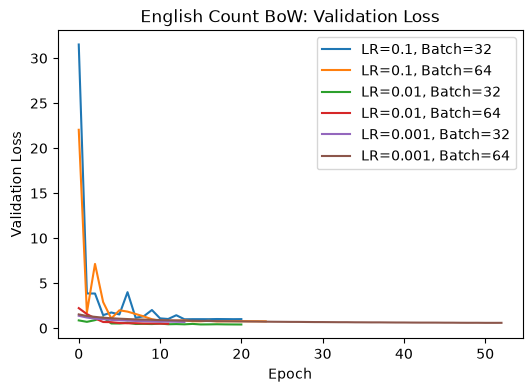

In [28]:
# Compare training configurations for the best-performing English feature representation.
import matplotlib.pyplot as plt

language = "eng"
feature = "count"

subset = results_df[
    (results_df["language"] == language) &
    (results_df["feature"] == feature) &
    (results_df["stage"] == "training")
]

plt.figure(figsize=(6, 4))

for _, row in subset.iterrows():
    plt.plot(
        row["dev_loss_curve"],
        label=f"LR={row['learning_rate']}, Batch={row['batch_size']}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("English Count BoW: Validation Loss")
plt.legend()
plt.show()

## 6. Softmax Weight Analysis

The best-performing English model is analysed to determine which words contribute most strongly to each news category. English is used because the learned word-category associations can be interpreted directly.

For each class, the words with the largest positive model weights are extracted. A larger positive weight indicates that the presence or frequency of that word provides stronger evidence for the corresponding class.

### 6.1 Retrieve the Best English Model

In [29]:
# Use the best-performing English feature representation from Task 5.
english_saved = best_models[("eng", "count")]

eng_best_model = english_saved["model"]
eng_best_vectorizer = english_saved["vectorizer"]
eng_best_encoder = english_saved["encoder"]

### 6.2 Extract Learned Weights

The linear layer contains one weight for every class-word pair. These weights are matched with the vocabulary learned by the Count BoW vectorizer.

In [30]:
weights = eng_best_model.linear.weight.detach().cpu().numpy()

feature_names = eng_best_vectorizer.get_feature_names_out()
class_names = eng_best_encoder.classes_

### 6.3 Identify the Highest-Weighted Words

Highest-Weighted Words per Class

The ten words with the largest positive weights are extracted for each English news category.

In [31]:
import numpy as np

top_n = 5
weight_summary = {}

for class_index, class_name in enumerate(class_names):
    indices = np.argsort(weights[class_index])[-top_n:][::-1]

    words_with_weights = [
        f"{feature_names[i]} ({weights[class_index, i]:.3f})"
        for i in indices
    ]

    weight_summary[class_name] = ", ".join(words_with_weights)

weight_table = pd.DataFrame(
    weight_summary.items(),
    columns=["Category", "Top weighted words"]
)
pd.set_option("display.max_colwidth", None)
display(weight_table)

,Category,Top weighted words
0,business,"business (1.385), prices (1.290), bank (1.103), energy (0.916), businesses (0.910)"
1,entertainment,"show (1.319), music (1.273), festival (1.069), film (1.068), song (0.967)"
2,health,"health (1.966), covid (1.469), ambulance (1.150), patients (1.123), nhs (1.117)"
3,politics,"sunak (2.031), government (1.571), scottish (1.474), party (1.203), welsh (1.160)"
4,sports,"sport (2.275), olympic (1.238), team (1.178), world (1.017), games (1.011)"
5,technology,"data (1.254), technology (1.187), tech (1.165), tiktok (1.151), cyber (1.084)"


### 6.4 Weight Interpretation

The learned weights show several plausible associations between keywords and news categories. Entertainment is strongly associated with words such as *music*, *show*, *film*, *art*, and *festival*, while health is associated with *health*, *covid*, *patients*, *ambulance*, and *hospital*. Sports similarly contains strongly relevant terms such as *sport*, *team*, *olympic*, *world*, and *games*.

Some associations appear more dataset-specific. For politics, *sunak*, *scottish*, and *labour* suggest that the model has learned associations with particular political figures, parties, or regions rather than only general political vocabulary. The technology association with *tiktok* may similarly reflect topics that occur frequently in technology articles in the training data. These associations can be useful for classification, but may generalise poorly if the people, organisations, or topics appearing in future articles change.

## 7. IsiXhosa Class Imbalance

The isiXhosa dataset is smaller and more imbalanced than the English dataset. To investigate whether class imbalance affects classification performance, two sampling strategies are evaluated:

- upsampling minority classes;
- downsampling majority classes.

The best isiXhosa feature representation and training hyperparameters from Task 5 are reused. Only the sampling rate is varied in these experiments.

### 7.1 Inspect the Class Distribution

The number of training examples in each isiXhosa category is examined first to identify the majority and minority classes.

In [32]:
xho_class_counts = xho_train["category"].value_counts()

display(
    xho_class_counts
    .rename_axis("Category")
    .reset_index(name="Training examples")
)

,Category,Training examples
0,entertainment,350
1,sports,347
2,politics,215
3,health,70
4,business,50


### 7.2 Prepare the Best isiXhosa Features

In [33]:
xho_best_config = best_models[("xho", "binary")]["config"]

xho_best_config

{'learning_rate': 0.1,
 'batch_size': 64,
 'vocab_size': 10000,
 'min_frequency': 3}

In [34]:
X_xho_train, X_xho_dev, X_xho_test, xho_vectorizer = extract_features(
    xho_train,
    xho_dev,
    xho_test,
    feature_type="binary",
    vocabulary_size=xho_best_config["vocab_size"],
    min_frequency=xho_best_config["min_frequency"]
)

y_xho_train, y_xho_dev, y_xho_test, xho_encoder = encode_labels(
    xho_train,
    xho_dev,
    xho_test
)

### 7.3 Training Function With a Sampler

For Task 7, PyTorch sampling needs to happen inside the DataLoader, so we make a small version that accepts a sampler.

In [35]:
def train_model_with_sampler(
    model,
    X_train,
    y_train,
    X_dev,
    y_dev,
    learning_rate,
    batch_size,
    sampler=None,
    max_epochs=50,
    patience=4
):
    train_dataset = TensorDataset(X_train, y_train)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=(sampler is None),
        sampler=sampler
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    best_dev_accuracy = -1.0
    best_model_state = None
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "dev_loss": [],
        "dev_accuracy": []
    }

    for epoch in range(max_epochs):
        model.train()
        total_train_loss = 0.0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * X_batch.size(0)

        average_train_loss = total_train_loss / len(train_loader.dataset)

        model.eval()

        with torch.no_grad():
            dev_logits = model(X_dev)
            dev_loss = criterion(dev_logits, y_dev).item()

            dev_predictions = torch.argmax(dev_logits, dim=1)

            dev_accuracy = (
                (dev_predictions == y_dev)
                .float()
                .mean()
                .item()
            )

        history["train_loss"].append(average_train_loss)
        history["dev_loss"].append(dev_loss)
        history["dev_accuracy"].append(dev_accuracy)

        if dev_accuracy > best_dev_accuracy:
            best_dev_accuracy = dev_accuracy

            best_model_state = {
                key: value.clone()
                for key, value in model.state_dict().items()
            }

            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_model_state)

    return model, history

### 7.4 Sampling Experiments

Different sampling rates are tested while keeping the best isiXhosa feature representation and training hyperparameters from Task 5 fixed.

#### 7.4.1 Upsampling Minority Classes

Minority classes are sampled more frequently during training using `WeightedRandomSampler`. The sampling rate controls how strongly each class is moved toward the size of the largest class. The remaining model and feature settings are kept fixed.

In [36]:
from torch.utils.data import WeightedRandomSampler

sampling_rates = [0.25, 0.50, 0.75, 1.00]

In [37]:
def create_upsampling_sampler(y_train, rate):
    class_counts = torch.bincount(y_train).float()
    max_count = class_counts.max()

    target_counts = class_counts + rate * (max_count - class_counts)

    class_weights = target_counts / class_counts
    sample_weights = class_weights[y_train]

    num_samples = int(target_counts.sum().item())

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=num_samples,
        replacement=True
    )

    return sampler

In [38]:
upsampling_results = []

for rate in sampling_rates:
    sampler = create_upsampling_sampler(
        y_xho_train,
        rate
    )

    model = MultinomialLogisticRegression(
        X_xho_train.shape[1],
        len(xho_encoder.classes_)
    )

    model, history = train_model_with_sampler(
        model,
        X_xho_train,
        y_xho_train,
        X_xho_dev,
        y_xho_dev,
        learning_rate=xho_best_config["learning_rate"],
        batch_size=xho_best_config["batch_size"],
        sampler=sampler
    )

    upsampling_results.append({
        "sampling_rate": rate,
        "val_accuracy": max(history["dev_accuracy"])
    })

upsampling_df = pd.DataFrame(upsampling_results)

display(upsampling_df)

,sampling_rate,val_accuracy
0,0.25,0.911565
1,0.50,0.918367
2,0.75,0.911565
3,1.00,0.918367


#### 7.4.2 Downsampling Majority Classes

Majority classes are sampled less frequently to reduce class imbalance. The sampling rate controls how strongly each class is moved toward the size of the smallest class, while the model and feature settings remain fixed.

Create the downsampling sampler

In [39]:
def create_downsampling_sampler(y_train, rate):
    class_counts = torch.bincount(y_train).float()
    min_count = class_counts.min()

    target_counts = class_counts - rate * (class_counts - min_count)

    class_weights = target_counts / class_counts
    sample_weights = class_weights[y_train]

    num_samples = int(target_counts.sum().item())

    return WeightedRandomSampler(
        weights=sample_weights,
        num_samples=num_samples,
        replacement=False
    )

Run the experiment

In [40]:
downsampling_results = []

for rate in sampling_rates:
    sampler = create_downsampling_sampler(
        y_xho_train,
        rate
    )

    model = MultinomialLogisticRegression(
        X_xho_train.shape[1],
        len(xho_encoder.classes_)
    )

    model, history = train_model_with_sampler(
        model,
        X_xho_train,
        y_xho_train,
        X_xho_dev,
        y_xho_dev,
        learning_rate=xho_best_config["learning_rate"],
        batch_size=xho_best_config["batch_size"],
        sampler=sampler
    )

    downsampling_results.append({
        "sampling_rate": rate,
        "val_accuracy": max(history["dev_accuracy"])
    })

downsampling_df = pd.DataFrame(downsampling_results)

display(downsampling_df)

,sampling_rate,val_accuracy
0,0.25,0.884354
1,0.50,0.843537
2,0.75,0.911565
3,1.00,0.918367


#### 7.4.3 Best Sampling Rates

The best sampling rate for each strategy is selected using validation accuracy. When two rates achieve the same validation accuracy, the less aggressive sampling rate is selected to retain a distribution closer to the original training data.

In [ ]:
best_up_rate = 0.25
best_down_rate = 0.75

best_up_sampler = create_upsampling_sampler(
    y_xho_train, best_up_rate
)

best_down_sampler = create_downsampling_sampler(
    y_xho_train, best_down_rate
)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
up_model = MultinomialLogisticRegression(
    X_xho_train.shape[1],
    len(xho_encoder.classes_)
)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
down_model = MultinomialLogisticRegression(
    X_xho_train.shape[1],
    len(xho_encoder.classes_)
)

up_model, _ = train_model_with_sampler(
    up_model,
    X_xho_train, y_xho_train,
    X_xho_dev, y_xho_dev,
    xho_best_config["learning_rate"],
    xho_best_config["batch_size"],
    sampler=best_up_sampler
)

down_model, _ = train_model_with_sampler(
    down_model,
    X_xho_train, y_xho_train,
    X_xho_dev, y_xho_dev,
    xho_best_config["learning_rate"],
    xho_best_config["batch_size"],
    sampler=best_down_sampler
)

### 7.5 Test-Set Comparison

The selected upsampling and downsampling models are evaluated on the unseen isiXhosa test set and compared with the best no-sampling model from Task 5.

In [141]:
baseline_model = best_models[("xho", "binary")]["model"]

def get_accuracy(model, X, y):
    model.eval()

    with torch.no_grad():
        predictions = model.predict(X)

    return (predictions == y).float().mean().item()


baseline_test_acc = get_accuracy(
    baseline_model, X_xho_test, y_xho_test
)

upsampling_test_acc = get_accuracy(
    up_model, X_xho_test, y_xho_test
)

downsampling_test_acc = get_accuracy(
    down_model, X_xho_test, y_xho_test
)

sampling_test_results = pd.DataFrame({
    "Strategy": [
        "No sampling",
        "Upsampling",
        "Downsampling"
    ],
    "Sampling rate": [
        0.00,
        0.25,
        0.75
    ],
    "Test accuracy": [
        0.892256,
        0.902357,
        0.878788
    ]
})


display(sampling_test_results)

,Strategy,Sampling rate,Test accuracy
0,No sampling,0.00,0.892256
1,Upsampling,0.25,0.902357
2,Downsampling,0.75,0.878788


Upsampling improved isiXhosa test accuracy from 89.23% to 90.24%, an increase of approximately 1.01 percentage points. In contrast, downsampling reduced test accuracy to 87.88%. This suggests that retaining the available training data while increasing the representation of minority classes was more effective than removing examples from the majority classes.

## 8. Bilingual Training

A single multinomial logistic regression model is trained on combined data from two languages. Two pairings are investigated: isiXhosa + chiShona and isiXhosa + English.

The best isiXhosa settings from Task 5 are reused: Binary Bag-of-Words, learning rate 0.1, batch size 32 and minimum frequency 0. Only vocabulary size is varied. A shared vocabulary is fitted on the combined training data for each language pair.

### 8.0 Prediction

I expect isiXhosa + chiShona to benefit isiXhosa more than isiXhosa + English because isiXhosa and chiShona are linguistically related and may share more useful lexical patterns. English is less closely related and may therefore provide less useful transfer to isiXhosa.

In [48]:
from sklearn.preprocessing import LabelEncoder

In [49]:
def encode_joint_labels(train_df):
    encoder = LabelEncoder()

    y_train = encoder.fit_transform(
        train_df["category"]
    )

    return torch.tensor(y_train, dtype=torch.long), encoder


def encode_with_encoder(dataframe, encoder):
    labels = encoder.transform(
        dataframe["category"]
    )

    return torch.tensor(labels, dtype=torch.long)

### 8.1 isiXhosa + chiShona Data

The isiXhosa and chiShona training sets are combined, while their development sets are combined separately. A language identifier is retained for analysis of vocabulary representation. Test sets remain separate for language-specific evaluation after model selection.

In [50]:
def add_language_column(dataframe, language):
    dataframe = dataframe.copy()
    dataframe["language"] = language
    return dataframe

In [51]:
xho_train_bi = add_language_column(xho_train, "xho")
xho_dev_bi = add_language_column(xho_dev, "xho")

sna_train_bi = add_language_column(sna_train, "sna")
sna_dev_bi = add_language_column(sna_dev, "sna")

xho_sna_train = pd.concat(
    [xho_train_bi, sna_train_bi],
    ignore_index=True
)

xho_sna_dev = pd.concat(
    [xho_dev_bi, sna_dev_bi],
    ignore_index=True
)

In [52]:
print("Training examples:")
print(xho_sna_train["language"].value_counts())

print("\nValidation examples:")
print(xho_sna_dev["language"].value_counts())

Training examples:
language
sna    1288
xho    1032
Name: count, dtype: int64

Validation examples:
language
sna    185
xho    147
Name: count, dtype: int64


### 8.2 Shared Feature Extraction

Binary Bag-of-Words is reused because it was the best-performing feature representation for isiXhosa in Task 5. A single vocabulary is fitted on the combined training text so that both languages use the same feature space.

Learning rate, batch size and minimum frequency remain fixed at the best Task 5 values. Vocabulary size is the only hyperparameter varied.

In [53]:
bilingual_vocab_sizes = [5000, 10000, 20000]

xho_best_config = best_models[("xho", "binary")]["config"]

### 8.3 Vocabulary Size Experiment

Vocabulary sizes of 5,000, 10,000 and 20,000 are compared using validation performance. For each size, one feature extractor is fitted on the combined training set and one model is trained on the resulting shared feature space.

The representation of each language in the learned vocabulary is also examined to determine whether the fixed vocabulary causes one language to crowd out the other.

In [117]:
xho_sna_results = []
xho_sna_models = {}

for vocab_size in bilingual_vocab_sizes:

    X_train, X_joint_dev, _, vectorizer = extract_features(
        xho_sna_train,
        xho_sna_dev,
        xho_sna_dev,
        feature_type="binary",
        vocabulary_size=vocab_size,
        min_frequency=xho_best_config["min_frequency"]
    )

    y_train, encoder = encode_joint_labels(
        xho_sna_train
    )

    y_joint_dev = encode_with_encoder(
        xho_sna_dev,
        encoder
    )
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = MultinomialLogisticRegression(
        X_train.shape[1],
        len(encoder.classes_)
    )

    model, history = train_model(
        model,
        X_train,
        y_train,
        X_joint_dev,
        y_joint_dev,
        learning_rate=xho_best_config["learning_rate"],
        batch_size=xho_best_config["batch_size"]
    )

    X_xho_dev_pair = torch.tensor(
        vectorizer.transform(
            xho_dev["clean_text"]
        ).toarray(),
        dtype=torch.float32
    )

    y_xho_dev_pair = encode_with_encoder(
        xho_dev,
        encoder
    )

    xho_val_accuracy = get_accuracy(
        model,
        X_xho_dev_pair,
        y_xho_dev_pair
    )

    xho_sna_results.append({
        "vocab_size": vocab_size,
        "joint_val_accuracy": max(history["dev_accuracy"]),
        "xho_val_accuracy": xho_val_accuracy
    })

    xho_sna_models[vocab_size] = {
        "model": model,
        "vectorizer": vectorizer,
        "encoder": encoder
    }

xho_sna_df = pd.DataFrame(xho_sna_results)

display(xho_sna_df)

Epoch   1 | Train Loss: 1.0308 | Dev Loss: 0.7814 | Dev Accuracy: 0.8163
Epoch   2 | Train Loss: 0.6462 | Dev Loss: 0.6285 | Dev Accuracy: 0.8404
Epoch   3 | Train Loss: 0.5162 | Dev Loss: 0.5608 | Dev Accuracy: 0.8373
Epoch   4 | Train Loss: 0.4423 | Dev Loss: 0.5126 | Dev Accuracy: 0.8584
Epoch   5 | Train Loss: 0.3895 | Dev Loss: 0.4835 | Dev Accuracy: 0.8494
Epoch   6 | Train Loss: 0.3498 | Dev Loss: 0.4601 | Dev Accuracy: 0.8705
Epoch   7 | Train Loss: 0.3185 | Dev Loss: 0.4436 | Dev Accuracy: 0.8645
Epoch   8 | Train Loss: 0.2925 | Dev Loss: 0.4316 | Dev Accuracy: 0.8675
Epoch   9 | Train Loss: 0.2710 | Dev Loss: 0.4203 | Dev Accuracy: 0.8675
Epoch  10 | Train Loss: 0.2530 | Dev Loss: 0.4106 | Dev Accuracy: 0.8705
Epoch  11 | Train Loss: 0.2371 | Dev Loss: 0.4047 | Dev Accuracy: 0.8675
Early stopping after epoch 11
Epoch   1 | Train Loss: 1.0242 | Dev Loss: 0.7619 | Dev Accuracy: 0.8283
Epoch   2 | Train Loss: 0.6225 | Dev Loss: 0.6183 | Dev Accuracy: 0.8283
Epoch   3 | Train Los

,vocab_size,joint_val_accuracy,xho_val_accuracy
0,5000,0.870482,0.863946
1,10000,0.873494,0.870748
2,20000,0.885542,0.911565


#### 8.3.1 Vocabulary Representation

For each vocabulary size, the learned vocabulary is compared with the terms occurring in each language's training data. Terms occurring in both languages are also counted separately because shared words contribute to the representation of both languages.

In [55]:
def get_language_vocabulary_terms(vectorizer, dataframe):
    vocabulary = set(
        vectorizer.get_feature_names_out()
    )

    language_terms = set(
        " ".join(dataframe["clean_text"]).split()
    )

    return vocabulary.intersection(language_terms)

In [56]:
vocab_source_results = []

for vocab_size in bilingual_vocab_sizes:
    vectorizer = xho_sna_models[vocab_size]["vectorizer"]

    xho_terms = get_language_vocabulary_terms(
        vectorizer, xho_train
    )

    sna_terms = get_language_vocabulary_terms(
        vectorizer, sna_train
    )

    shared_terms = xho_terms.intersection(sna_terms)

    vocab_source_results.append({
        "vocab_size": vocab_size,
        "xho_terms": len(xho_terms),
        "sna_terms": len(sna_terms),
        "shared_terms": len(shared_terms)
    })

xho_sna_vocab_df = pd.DataFrame(vocab_source_results)

display(xho_sna_vocab_df)

,vocab_size,xho_terms,sna_terms,shared_terms
0,5000,2478,3037,515
1,10000,5208,5654,862
2,20000,10940,10437,1377


### 8.4 Best Vocabulary Selection

A vocabulary size of 20,000 was selected for isiXhosa + chiShona because it achieved the highest isiXhosa validation accuracy (91.16%). It also provided strong representation of both languages, with 10,950 isiXhosa terms and 10,461 chiShona terms in the shared vocabulary.

In [57]:
best_xho_sna_vocab = 20000

best_xho_sna = xho_sna_models[
    best_xho_sna_vocab
]

xho_sna_model = best_xho_sna["model"]
xho_sna_vectorizer = best_xho_sna["vectorizer"]
xho_sna_encoder = best_xho_sna["encoder"]

### 8.5 Separate Test Evaluation

The selected joint model is evaluated separately on the isiXhosa and chiShona test sets. Both test sets are transformed using the same shared feature extractor fitted on the combined training data.

In [58]:
def transform_bilingual_test(
    dataframe,
    vectorizer,
    encoder
):
    X_test = torch.tensor(
        vectorizer.transform(
            dataframe["clean_text"]
        ).toarray(),
        dtype=torch.float32
    )

    y_test = encode_with_encoder(
        dataframe,
        encoder
    )

    return X_test, y_test

Transform both

In [59]:
X_xho_test_bi, y_xho_test_bi = transform_bilingual_test(
    xho_test,
    xho_sna_vectorizer,
    xho_sna_encoder
)

X_sna_test_bi, y_sna_test_bi = transform_bilingual_test(
    sna_test,
    xho_sna_vectorizer,
    xho_sna_encoder
)

Evaluate the same model twice:

In [60]:
xho_sna_xho_test_acc = get_accuracy(
    xho_sna_model,
    X_xho_test_bi,
    y_xho_test_bi
)

xho_sna_sna_test_acc = get_accuracy(
    xho_sna_model,
    X_sna_test_bi,
    y_sna_test_bi
)

xho_sna_test_results = pd.DataFrame({
    "Test language": ["isiXhosa", "chiShona"],
    "Test accuracy": [
        xho_sna_xho_test_acc,
        xho_sna_sna_test_acc
    ]
})

display(xho_sna_test_results)

,Test language,Test accuracy
0,isiXhosa,0.888889
1,chiShona,0.913279


### 8.6 isiXhosa + English

The second bilingual model combines isiXhosa and English. The same procedure used for isiXhosa + chiShona is followed so that the two pairings can be compared fairly. Binary Bag-of-Words, learning rate, batch size and minimum frequency remain fixed, while vocabulary size is varied.

#### 8.6.1 Combined Data

The isiXhosa and English training sets are combined, while their development sets are combined separately. Language identifiers are retained for vocabulary analysis, and the test sets remain separate.

In [61]:
eng_train_bi = add_language_column(
    eng_train, "eng"
)

eng_dev_bi = add_language_column(
    eng_dev, "eng"
)

xho_eng_train = pd.concat(
    [xho_train_bi, eng_train_bi],
    ignore_index=True
)

xho_eng_dev = pd.concat(
    [xho_dev_bi, eng_dev_bi],
    ignore_index=True
)

In [62]:
print("Training examples:")
print(xho_eng_train["language"].value_counts())

print("\nValidation examples:")
print(xho_eng_dev["language"].value_counts())

Training examples:
language
eng    3309
xho    1032
Name: count, dtype: int64

Validation examples:
language
eng    472
xho    147
Name: count, dtype: int64


#### 8.6.2 Vocabulary Size Experiment

Shared vocabulary sizes of 5,000, 10,000 and 20,000 are evaluated. For each size, one feature extractor is fitted on the combined training data and one joint model is trained. isiXhosa validation accuracy is recorded to determine which vocabulary size best supports isiXhosa classification.

In [116]:
xho_eng_results = []
xho_eng_models = {}

for vocab_size in bilingual_vocab_sizes:

    X_train, X_joint_dev, _, vectorizer = extract_features(
        xho_eng_train,
        xho_eng_dev,
        xho_eng_dev,
        feature_type="binary",
        vocabulary_size=vocab_size,
        min_frequency=xho_best_config["min_frequency"]
    )

    y_train, encoder = encode_joint_labels(
        xho_eng_train
    )

    y_joint_dev = encode_with_encoder(
        xho_eng_dev,
        encoder
    )
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = MultinomialLogisticRegression(
        X_train.shape[1],
        len(encoder.classes_)
    )

    model, history = train_model(
        model,
        X_train,
        y_train,
        X_joint_dev,
        y_joint_dev,
        learning_rate=xho_best_config["learning_rate"],
        batch_size=xho_best_config["batch_size"]
    )

    X_xho_dev_pair = torch.tensor(
        vectorizer.transform(
            xho_dev["clean_text"]
        ).toarray(),
        dtype=torch.float32
    )

    y_xho_dev_pair = encode_with_encoder(
        xho_dev,
        encoder
    )

    xho_val_accuracy = get_accuracy(
        model,
        X_xho_dev_pair,
        y_xho_dev_pair
    )

    xho_eng_results.append({
        "vocab_size": vocab_size,
        "joint_val_accuracy": max(history["dev_accuracy"]),
        "xho_val_accuracy": xho_val_accuracy
    })

    xho_eng_models[vocab_size] = {
        "model": model,
        "vectorizer": vectorizer,
        "encoder": encoder
    }

xho_eng_df = pd.DataFrame(xho_eng_results)

display(xho_eng_df)

Epoch   1 | Train Loss: 1.1047 | Dev Loss: 0.7884 | Dev Accuracy: 0.8013
Epoch   2 | Train Loss: 0.6681 | Dev Loss: 0.6387 | Dev Accuracy: 0.8304
Epoch   3 | Train Loss: 0.5356 | Dev Loss: 0.5740 | Dev Accuracy: 0.8352
Epoch   4 | Train Loss: 0.4614 | Dev Loss: 0.5294 | Dev Accuracy: 0.8514
Epoch   5 | Train Loss: 0.4080 | Dev Loss: 0.5025 | Dev Accuracy: 0.8530
Epoch   6 | Train Loss: 0.3669 | Dev Loss: 0.4851 | Dev Accuracy: 0.8498
Epoch   7 | Train Loss: 0.3349 | Dev Loss: 0.4689 | Dev Accuracy: 0.8675
Epoch   8 | Train Loss: 0.3089 | Dev Loss: 0.4561 | Dev Accuracy: 0.8643
Epoch   9 | Train Loss: 0.2866 | Dev Loss: 0.4468 | Dev Accuracy: 0.8611
Epoch  10 | Train Loss: 0.2672 | Dev Loss: 0.4396 | Dev Accuracy: 0.8643
Epoch  11 | Train Loss: 0.2508 | Dev Loss: 0.4336 | Dev Accuracy: 0.8708
Epoch  12 | Train Loss: 0.2368 | Dev Loss: 0.4288 | Dev Accuracy: 0.8724
Epoch  13 | Train Loss: 0.2235 | Dev Loss: 0.4242 | Dev Accuracy: 0.8659
Epoch  14 | Train Loss: 0.2124 | Dev Loss: 0.4205 |

,vocab_size,joint_val_accuracy,xho_val_accuracy
0,5000,0.872375,0.877551
1,10000,0.880452,0.897959
2,20000,0.878837,0.904762


#### 8.6.3 Vocabulary Representation

The shared vocabulary is examined to determine how strongly isiXhosa and English are represented at each vocabulary size. This is used to check whether the larger English dataset crowds isiXhosa terms out of the shared feature space.

In [64]:
xho_eng_vocab_results = []

for vocab_size in bilingual_vocab_sizes:
    vectorizer = xho_eng_models[vocab_size]["vectorizer"]

    xho_terms = get_language_vocabulary_terms(
        vectorizer, xho_train
    )

    eng_terms = get_language_vocabulary_terms(
        vectorizer, eng_train
    )

    shared_terms = xho_terms.intersection(eng_terms)

    xho_eng_vocab_results.append({
        "vocab_size": vocab_size,
        "xho_terms": len(xho_terms),
        "eng_terms": len(eng_terms),
        "shared_terms": len(shared_terms)
    })

xho_eng_vocab_df = pd.DataFrame(
    xho_eng_vocab_results
)

display(xho_eng_vocab_df)

,vocab_size,xho_terms,eng_terms,shared_terms
0,5000,2061,4256,1317
1,10000,3935,7890,1825
2,20000,8440,13938,2378


#### 8.6.4 Best Vocabulary Selection

A vocabulary size of 20,000 was selected because it achieved the highest isiXhosa validation accuracy (91.84%). Increasing vocabulary size also improved isiXhosa representation in the shared feature space from 2,060 terms at 5,000 vocabulary features to 8,547 terms at 20,000.

In [65]:
best_xho_eng_vocab = 20000

best_xho_eng = xho_eng_models[
    best_xho_eng_vocab
]

xho_eng_model = best_xho_eng["model"]
xho_eng_vectorizer = best_xho_eng["vectorizer"]
xho_eng_encoder = best_xho_eng["encoder"]

#### 8.6.5 Separate Test Evaluation

The selected joint model is evaluated separately on the isiXhosa and English test sets using the same shared feature extractor.

In [66]:
X_xho_test_bi, y_xho_test_bi = transform_bilingual_test(
    xho_test,
    xho_eng_vectorizer,
    xho_eng_encoder
)

X_eng_test_bi, y_eng_test_bi = transform_bilingual_test(
    eng_test,
    xho_eng_vectorizer,
    xho_eng_encoder
)

Then evaluate the same model on both:

In [67]:
xho_eng_xho_test_acc = get_accuracy(
    xho_eng_model,
    X_xho_test_bi,
    y_xho_test_bi
)

xho_eng_eng_test_acc = get_accuracy(
    xho_eng_model,
    X_eng_test_bi,
    y_eng_test_bi
)

xho_eng_test_results = pd.DataFrame({
    "Test language": ["isiXhosa", "English"],
    "Test accuracy": [
        xho_eng_xho_test_acc,
        xho_eng_eng_test_acc
    ]
})

display(xho_eng_test_results)

,Test language,Test accuracy
0,isiXhosa,0.882155
1,English,0.890295


### 8.7 Bilingual Comparison

The best vocabulary size for both language pairings was 20,000. The selected bilingual models are compared using their isiXhosa validation and test performance to determine whether joint training improved on the original isiXhosa model.

In [142]:
bilingual_comparison = pd.DataFrame({
    "Model": [
        "No bilingual training",
        "isiXhosa + chiShona",
        "isiXhosa + English"
    ],
    "Vocabulary size": [
        10000,
        20000,
        20000
    ],
    "isiXhosa val accuracy": [
        0.925170,
        0.911565,
        0.918367
    ],
    "isiXhosa test accuracy": [
        0.892256,
        0.885522,
        0.898990
    ]
})

display(bilingual_comparison)

,Model,Vocabulary size,isiXhosa val accuracy,isiXhosa test accuracy
0,No bilingual training,10000,0.925170,0.892256
1,isiXhosa + chiShona,20000,0.911565,0.885522
2,isiXhosa + English,20000,0.918367,0.898990


### 8.7 Consolidated isiXhosa Result

In [143]:
xho_summary = pd.DataFrame({
    "Experiment": [
        "Task 5 baseline",
        "Task 7 upsampling",
        "Task 7 downsampling",
        "Task 8 xho + sna",
        "Task 8 xho + eng"
    ],
    "Test accuracy": [
        0.892256,
        0.902357,
        0.878788,
        0.885522,
        0.898990
    ]
})

display(xho_summary)

,Experiment,Test accuracy
0,Task 5 baseline,0.892256
1,Task 7 upsampling,0.902357
2,Task 7 downsampling,0.878788
3,Task 8 xho + sna,0.885522
4,Task 8 xho + eng,0.898990


In [122]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

xho_sna_model = xho_sna_models[best_xho_sna_vocab]["model"]
xho_sna_vectorizer = xho_sna_models[best_xho_sna_vocab]["vectorizer"]
xho_sna_encoder = xho_sna_models[best_xho_sna_vocab]["encoder"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

xho_eng_model = xho_eng_models[best_xho_eng_vocab]["model"]
xho_eng_vectorizer = xho_eng_models[best_xho_eng_vocab]["vectorizer"]
xho_eng_encoder = xho_eng_models[best_xho_eng_vocab]["encoder"]

In [124]:
# Final seeded xho + sna model
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

X_train, X_dev, _, xho_sna_vectorizer = extract_features(
    xho_sna_train,
    xho_sna_dev,
    xho_sna_dev,
    feature_type="binary",
    vocabulary_size=20000,
    min_frequency=0
)

y_train, xho_sna_encoder = encode_joint_labels(xho_sna_train)
y_dev = encode_with_encoder(xho_sna_dev, xho_sna_encoder)

xho_sna_model = MultinomialLogisticRegression(
    X_train.shape[1],
    len(xho_sna_encoder.classes_)
)

xho_sna_model, _ = train_model(
    xho_sna_model,
    X_train,
    y_train,
    X_dev,
    y_dev,
    learning_rate=0.1,
    batch_size=32,
    max_epochs=50,
    patience=4
)


# Final seeded xho + eng model
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

X_train, X_dev, _, xho_eng_vectorizer = extract_features(
    xho_eng_train,
    xho_eng_dev,
    xho_eng_dev,
    feature_type="binary",
    vocabulary_size=20000,
    min_frequency=0
)

y_train, xho_eng_encoder = encode_joint_labels(xho_eng_train)
y_dev = encode_with_encoder(xho_eng_dev, xho_eng_encoder)

xho_eng_model = MultinomialLogisticRegression(
    X_train.shape[1],
    len(xho_eng_encoder.classes_)
)

xho_eng_model, _ = train_model(
    xho_eng_model,
    X_train,
    y_train,
    X_dev,
    y_dev,
    learning_rate=0.1,
    batch_size=32,
    max_epochs=50,
    patience=4
)

Epoch   1 | Train Loss: 0.8523 | Dev Loss: 0.6099 | Dev Accuracy: 0.8404
Epoch   2 | Train Loss: 0.4443 | Dev Loss: 0.4914 | Dev Accuracy: 0.8494
Epoch   3 | Train Loss: 0.3250 | Dev Loss: 0.4407 | Dev Accuracy: 0.8614
Epoch   4 | Train Loss: 0.2573 | Dev Loss: 0.4139 | Dev Accuracy: 0.8735
Epoch   5 | Train Loss: 0.2122 | Dev Loss: 0.3933 | Dev Accuracy: 0.8705
Epoch   6 | Train Loss: 0.1806 | Dev Loss: 0.3796 | Dev Accuracy: 0.8705
Epoch   7 | Train Loss: 0.1567 | Dev Loss: 0.3679 | Dev Accuracy: 0.8825
Epoch   8 | Train Loss: 0.1376 | Dev Loss: 0.3614 | Dev Accuracy: 0.8795
Epoch   9 | Train Loss: 0.1230 | Dev Loss: 0.3545 | Dev Accuracy: 0.8825
Epoch  10 | Train Loss: 0.1108 | Dev Loss: 0.3487 | Dev Accuracy: 0.8886
Epoch  11 | Train Loss: 0.1008 | Dev Loss: 0.3446 | Dev Accuracy: 0.8855
Epoch  12 | Train Loss: 0.0923 | Dev Loss: 0.3404 | Dev Accuracy: 0.8795
Epoch  13 | Train Loss: 0.0852 | Dev Loss: 0.3376 | Dev Accuracy: 0.8855
Epoch  14 | Train Loss: 0.0790 | Dev Loss: 0.3356 |

In [125]:
X_xho_sna_test, y_xho_sna_test = transform_bilingual_test(
    xho_test,
    xho_sna_vectorizer,
    xho_sna_encoder
)

X_xho_eng_test, y_xho_eng_test = transform_bilingual_test(
    xho_test,
    xho_eng_vectorizer,
    xho_eng_encoder
)

print(
    "xho+sna isiXhosa test accuracy:",
    get_accuracy(xho_sna_model, X_xho_sna_test, y_xho_sna_test)
)

print(
    "xho+eng isiXhosa test accuracy:",
    get_accuracy(xho_eng_model, X_xho_eng_test, y_xho_eng_test)
)

xho+sna isiXhosa test accuracy: 0.8855218887329102
xho+eng isiXhosa test accuracy: 0.8989899158477783


### 8.8 Discussion

The prediction that isiXhosa + chiShona would improve isiXhosa performance more was not supported. The isiXhosa + chiShona model achieved a test accuracy of 88.55%, which was lower than the 89.23% baseline. The isiXhosa + English model performed better, reaching 89.90%, which was slightly higher than the baseline.

Increasing the vocabulary size improved isiXhosa representation in the shared feature space, especially for the isiXhosa + English pairing where the smaller vocabulary was more strongly dominated by English terms.

## 9. Evaluation

Task 9 evaluates the models already selected in the earlier experiments. The best Task 5 model for each language is evaluated on its own test set. For isiXhosa, the baseline, sampling and bilingual models are also compared so that changes in minority-class performance can be examined.

The evaluation reports accuracy, precision, recall and F1-score using both micro- and macro-averaging.

### 9.1 Evaluation Metrics

A reusable evaluation function is used to calculate accuracy together with micro- and macro-averaged precision, recall and F1-score. The `average` parameter in the scikit-learn metric functions controls whether micro- or macro-averaging is used.

In [126]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Micro Precision": precision_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "Micro Recall": recall_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "Micro F1": f1_score(
            y_true, y_pred, average="micro", zero_division=0
        ),

        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

### 9.2 Overall Test Performance

The best-performing feature representation from Task 5 is used for each language. Each selected model is evaluated once on its corresponding test set and the results are stored in a single table.

In [139]:
task5_best = {
    "English": ("eng", "count", eng_test),
    "chiShona": ("sna", "count", sna_test),
    "isiXhosa": ("xho", "binary", xho_test)
}

task5_metric_rows = []

for name, (language, feature, test_df) in task5_best.items():

    saved = best_models[(language, feature)]

    model = saved["model"]
    vectorizer = saved["vectorizer"]
    encoder = saved["encoder"]

    X_test = torch.tensor(
        vectorizer.transform(
            test_df["clean_text"]
        ).toarray(),
        dtype=torch.float32
    )

    y_test = encode_with_encoder(
        test_df,
        encoder
    )

    model.eval()

    with torch.no_grad():
        y_pred = model.predict(X_test)

    metrics = calculate_metrics(
        y_test.numpy(),
        y_pred.numpy()
    )

    metrics["Model"] = name
    task5_metric_rows.append(metrics)

In [144]:
task5_metrics_df = pd.DataFrame(task5_metric_rows)

task5_metrics_df = task5_metrics_df[
    [
        "Model",
        "Accuracy",
        "Micro Precision",
        "Micro Recall",
        "Micro F1",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]
]

display(task5_metrics_df.round(4))

,Model,Accuracy,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1
0,English,0.8882,0.8882,0.8882,0.8882,0.8839,0.8824,0.8828
1,chiShona,0.9133,0.9133,0.9133,0.9133,0.9200,0.9151,0.9159
2,isiXhosa,0.8923,0.8923,0.8923,0.8923,0.8914,0.7230,0.7584


In [145]:
# Evaluate best isiXhosa model from Task 7

up_model.eval()

with torch.no_grad():
    up_pred = up_model.predict(X_xho_test)

up_metrics = calculate_metrics(
    y_xho_test.numpy(),
    up_pred.numpy()
)

up_metrics["Model"] = "isiXhosa Upsampling"

up_metrics_df = pd.DataFrame([up_metrics])

display(up_metrics_df)

,Accuracy,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Model
0,0.902357,0.902357,0.902357,0.902357,0.896357,0.764323,0.799041,isiXhosa Upsampling


### 9.3 Micro and Macro Performance

Micro-averaged metrics give greater influence to classes with more examples, while macro-averaged metrics give equal importance to every class. Comparing the two is therefore particularly useful for isiXhosa, where the class distribution is imbalanced.

In [128]:
micro_macro_df = task5_metrics_df[
    [
        "Model",
        "Micro Precision",
        "Micro Recall",
        "Micro F1",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]
].copy()

display(micro_macro_df.round(4))

,Model,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1
0,English,0.8882,0.8882,0.8882,0.8839,0.8824,0.8828
1,chiShona,0.9133,0.9133,0.9133,0.9200,0.9151,0.9159
2,isiXhosa,0.9057,0.9057,0.9057,0.8948,0.7595,0.7940


For an explicit F1 gap

In [73]:
micro_macro_df["F1 Gap"] = (
    micro_macro_df["Micro F1"]
    - micro_macro_df["Macro F1"]
)

display(
    micro_macro_df[
        ["Model", "Micro F1", "Macro F1", "F1 Gap"]
    ].round(4)
)

,Model,Micro F1,Macro F1,F1 Gap
0,English,0.8882,0.8828,0.0054
1,chiShona,0.9133,0.9159,-0.0026
2,isiXhosa,0.9057,0.7940,0.1117


### 9.4 Confusion Matrices

Confusion matrices are generated using the final Task 5 models to show how predictions are distributed across categories. Class names are displayed directly so that reliable categories and common misclassifications can be identified.

In [74]:
def plot_confusion_matrix(
    model,
    X_test,
    y_test,
    encoder,
    title
):
    model.eval()

    with torch.no_grad():
        y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test.numpy(),
        y_pred.numpy()
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=encoder.classes_
    )

    display.plot()
    plt.title(title)
    plt.xticks(rotation=45)
    plt.show()

    return cm

generating one for each language

English

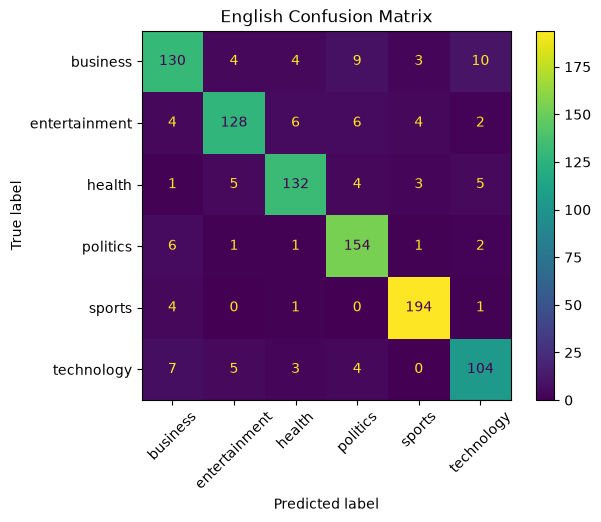

In [75]:
saved = best_models[("eng", "count")]

eng_model = saved["model"]
eng_vectorizer = saved["vectorizer"]
eng_encoder = saved["encoder"]

X_eng_test = torch.tensor(
    eng_vectorizer.transform(
        eng_test["clean_text"]
    ).toarray(),
    dtype=torch.float32
)

y_eng_test = encode_with_encoder(
    eng_test,
    eng_encoder
)

eng_cm = plot_confusion_matrix(
    eng_model,
    X_eng_test,
    y_eng_test,
    eng_encoder,
    "English Confusion Matrix"
)

chiShona

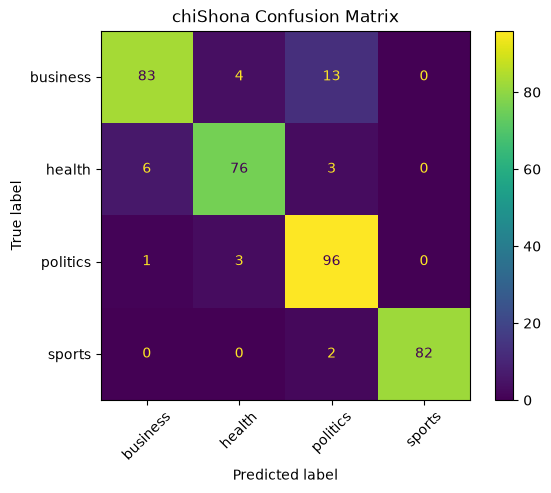

In [76]:
saved = best_models[("sna", "count")]

sna_model = saved["model"]
sna_vectorizer = saved["vectorizer"]
sna_encoder = saved["encoder"]

X_sna_test = torch.tensor(
    sna_vectorizer.transform(
        sna_test["clean_text"]
    ).toarray(),
    dtype=torch.float32
)

y_sna_test = encode_with_encoder(
    sna_test,
    sna_encoder
)

sna_cm = plot_confusion_matrix(
    sna_model,
    X_sna_test,
    y_sna_test,
    sna_encoder,
    "chiShona Confusion Matrix"
)

isiXhosa

In [129]:
xho_model = best_models[("xho", "binary")]["model"]

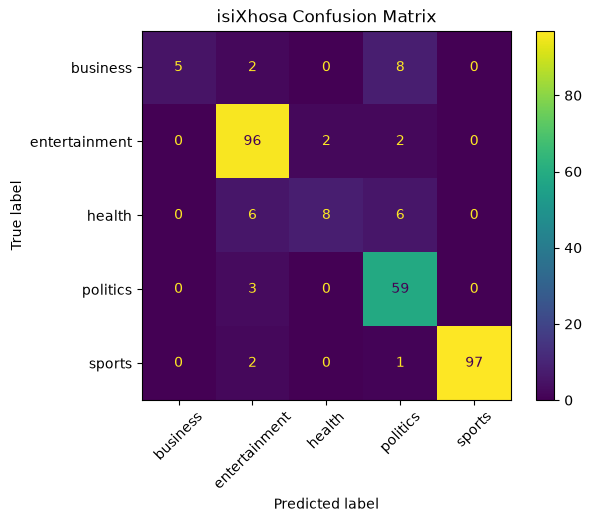

In [130]:
saved = best_models[("xho", "binary")]

xho_model = saved["model"]
xho_vectorizer = saved["vectorizer"]
xho_encoder = saved["encoder"]

X_xho_test = torch.tensor(
    xho_vectorizer.transform(
        xho_test["clean_text"]
    ).toarray(),
    dtype=torch.float32
)

y_xho_test = encode_with_encoder(
    xho_test,
    xho_encoder
)

xho_cm = plot_confusion_matrix(
    xho_model,
    X_xho_test,
    y_xho_test,
    xho_encoder,
    "isiXhosa Confusion Matrix"
)

The isiXhosa confusion matrix shows that sports, politics and entertainment are classified most reliably, while business and health are more difficult. Business is most frequently confused with politics, while health is commonly confused with politics and entertainment. This is consistent with the class imbalance in the isiXhosa training data, where business and health have substantially fewer training examples.

### 9.5 Per-Class Performance

Per-class recall is calculated from each confusion matrix. Recall measures the proportion of examples from a category that were correctly classified and helps identify which categories are recognised most reliably.

In [78]:
def recall_from_confusion_matrix(cm, class_names):
    recalls = cm.diagonal() / cm.sum(axis=1)

    return pd.DataFrame({
        "Category": class_names,
        "Recall": recalls
    }).sort_values(
        "Recall",
        ascending=False
    )

isiXhosa example

In [79]:
xho_recall_df = recall_from_confusion_matrix(
    xho_cm,
    xho_encoder.classes_
)

display(xho_recall_df.round(4))

,Category,Recall
4,sports,0.9800
3,politics,0.9677
1,entertainment,0.9500
2,health,0.5000
0,business,0.4000


extracting the largest off-diagonal mistakes.

In [80]:
def most_confused_pairs(cm, class_names):
    rows = []

    for actual in range(len(class_names)):
        for predicted in range(len(class_names)):

            if actual != predicted and cm[actual, predicted] > 0:
                rows.append({
                    "Actual": class_names[actual],
                    "Predicted": class_names[predicted],
                    "Count": cm[actual, predicted]
                })

    return pd.DataFrame(rows).sort_values(
        "Count",
        ascending=False
    )

In [81]:
xho_confused_df = most_confused_pairs(
    xho_cm,
    xho_encoder.classes_
)

display(xho_confused_df.head(10))

,Actual,Predicted,Count
1,business,politics,7
5,health,politics,5
4,health,entertainment,5
2,entertainment,health,3
0,business,entertainment,2
3,entertainment,politics,2
6,politics,entertainment,2
7,sports,entertainment,1
8,sports,politics,1


### 9.6 Rare-Class Performance

The isiXhosa training data is imbalanced, with business and health having substantially fewer examples than the other categories. Per-class precision, recall and F1-score are therefore compared across the baseline, sampling and bilingual experiments to determine whether Tasks 7 or 8 improved performance on these rarer categories.

In [88]:
def get_per_class_metrics(model, X_test, y_test, encoder, model_name):
    model.eval()

    with torch.no_grad():
        y_pred = model.predict(X_test)

    present_labels = sorted(y_test.unique().tolist())
    present_names = encoder.inverse_transform(present_labels)

    report = classification_report(
        y_test.numpy(),
        y_pred.numpy(),
        labels=present_labels,
        target_names=present_names,
        output_dict=True,
        zero_division=0
    )

    rows = []

    for category in present_names:
        rows.append({
            "Model": model_name,
            "Category": category,
            "Precision": report[category]["precision"],
            "Recall": report[category]["recall"],
            "F1": report[category]["f1-score"],
            "Support": report[category]["support"]
        })

    return rows

baseline isiXhosa

In [131]:
xho_per_class_rows = []

baseline_saved = best_models[("xho", "binary")]

baseline_model = baseline_saved["model"]
baseline_vectorizer = baseline_saved["vectorizer"]
baseline_encoder = baseline_saved["encoder"]

X_xho_baseline_test = torch.tensor(
    baseline_vectorizer.transform(
        xho_test["clean_text"]
    ).toarray(),
    dtype=torch.float32
)

y_xho_baseline_test = encode_with_encoder(
    xho_test,
    baseline_encoder
)

xho_per_class_rows.extend(
    get_per_class_metrics(
        baseline_model,
        X_xho_baseline_test,
        y_xho_baseline_test,
        baseline_encoder,
        "Baseline"
    )
)

In [132]:
baseline_class_df = pd.DataFrame(xho_per_class_rows)

display(
    baseline_class_df[
        baseline_class_df["Category"].isin(
            ["business", "health"]
        )
    ].round(4)
)

,Model,Category,Precision,Recall,F1,Support
0,Baseline,business,1.0,0.3333,0.5000,15.0
2,Baseline,health,0.8,0.4000,0.5333,20.0


xho + chiShona

In [133]:
X_xho_sna_test = torch.tensor(
    xho_sna_vectorizer.transform(
        xho_test["clean_text"]
    ).toarray(),
    dtype=torch.float32
)

y_xho_sna_test = encode_with_encoder(
    xho_test,
    xho_sna_encoder
)

xho_per_class_rows.extend(
    get_per_class_metrics(
        xho_sna_model,
        X_xho_sna_test,
        y_xho_sna_test,
        xho_sna_encoder,
        "xho + sna"
    )
)

xho + English

In [135]:
X_xho_eng_test = torch.tensor(
    xho_eng_vectorizer.transform(
        xho_test["clean_text"]
    ).toarray(),
    dtype=torch.float32
)

y_xho_eng_test = encode_with_encoder(
    xho_test,
    xho_eng_encoder
)

xho_per_class_rows.extend(
    get_per_class_metrics(
        xho_eng_model,
        X_xho_eng_test,
        y_xho_eng_test,
        xho_eng_encoder,
        "xho + eng"
    )
)

Adding the upsampling model

In [136]:
xho_per_class_rows.extend(
    get_per_class_metrics(
        up_model,
        X_xho_baseline_test,
        y_xho_baseline_test,
        baseline_encoder,
        "Upsampling"
    )
)

Adding the downsampling model

In [137]:
xho_per_class_rows.extend(
    get_per_class_metrics(
        down_model,
        X_xho_baseline_test,
        y_xho_baseline_test,
        baseline_encoder,
        "Downsampling"
    )
)

In [138]:
xho_per_class_df = pd.DataFrame(xho_per_class_rows)

display(
    xho_per_class_df[
        ["Model", "Category", "Precision", "Recall", "F1", "Support"]
    ].round(4)
)

,Model,Category,Precision,Recall,F1,Support
0,Baseline,business,1.0000,0.3333,0.5000,15.0
1,Baseline,entertainment,0.8807,0.9600,0.9187,100.0
2,Baseline,health,0.8000,0.4000,0.5333,20.0
3,Baseline,politics,0.7763,0.9516,0.8551,62.0
4,Baseline,sports,1.0000,0.9700,0.9848,100.0
5,xho + sna,business,1.0000,0.3333,0.5000,15.0
6,xho + sna,entertainment,0.8716,0.9500,0.9091,100.0
7,xho + sna,health,0.7273,0.4000,0.5161,20.0
8,xho + sna,politics,0.7733,0.9355,0.8467,62.0
9,xho + sna,sports,1.0000,0.9700,0.9848,100.0


Upsampling provided the strongest minority-class performance among the Task 7 and Task 8 alternatives. Business recall remained at 40.0%, matching the baseline, while health F1 improved from 0.6061 to 0.6250. The bilingual models did not improve the rarer classes overall, with isiXhosa + English reducing business recall to 13.3%.

In [97]:
rare_classes_df = xho_per_class_df[
    xho_per_class_df["Category"].isin(
        ["business", "health"]
    )
]

display(
    rare_classes_df[
        ["Model", "Category", "Precision", "Recall", "F1", "Support"]
    ].round(4)
)

,Model,Category,Precision,Recall,F1,Support
0,Baseline,business,1.0000,0.4000,0.5714,15.0
2,Baseline,health,0.7692,0.5000,0.6061,20.0
5,xho + sna,business,1.0000,0.2667,0.4211,15.0
7,xho + sna,health,0.8000,0.4000,0.5333,20.0
10,xho + eng,business,1.0000,0.1333,0.2353,15.0
12,xho + eng,health,0.8000,0.4000,0.5333,20.0
15,Upsampling,business,1.0000,0.4000,0.5714,15.0
17,Upsampling,health,0.8333,0.5000,0.6250,20.0
20,Downsampling,business,1.0000,0.3333,0.5000,15.0
22,Downsampling,health,0.8182,0.4500,0.5806,20.0


### 9.7 Final Evaluation Summary

The final evaluation brings together the overall test metrics, micro- and macro-averaged results, confusion matrices, and per-class isiXhosa performance. These results are used to compare performance across languages, identify common classification errors, and determine whether the sampling or bilingual experiments improved performance on the rarer isiXhosa categories.

Across the Task 5 models, English achieved 88.82% test accuracy, chiShona achieved 91.33%, and the isiXhosa baseline achieved 89.23%. Micro- and macro-averaged scores were similar for English and chiShona, whereas isiXhosa showed a larger gap, with a micro-F1 of 89.23% and macro-F1 of 75.84%. This indicates weaker performance across the less represented isiXhosa classes.

Upsampling produced the best final isiXhosa model, increasing test accuracy to 90.24% and macro-F1 to 79.90%. It also slightly improved health F1 while maintaining business recall. In contrast, downsampling reduced overall accuracy, and the bilingual models did not improve performance on the rarer isiXhosa classes overall.

In [98]:
rare_class_summary = rare_classes_df[
    ["Model", "Category", "Recall", "F1"]
].copy()

display(rare_class_summary.round(4))

,Model,Category,Recall,F1
0,Baseline,business,0.4000,0.5714
2,Baseline,health,0.5000,0.6061
5,xho + sna,business,0.2667,0.4211
7,xho + sna,health,0.4000,0.5333
10,xho + eng,business,0.1333,0.2353
12,xho + eng,health,0.4000,0.5333
15,Upsampling,business,0.4000,0.5714
17,Upsampling,health,0.5000,0.6250
20,Downsampling,business,0.3333,0.5000
22,Downsampling,health,0.4500,0.5806


In [99]:
display(task5_metrics_df.round(4))

,Model,Accuracy,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1
0,English,0.8882,0.8882,0.8882,0.8882,0.8839,0.8824,0.8828
1,chiShona,0.9133,0.9133,0.9133,0.9133,0.9200,0.9151,0.9159
2,isiXhosa,0.9057,0.9057,0.9057,0.9057,0.8948,0.7595,0.7940


In [100]:
display(
    micro_macro_df[
        ["Model", "Micro F1", "Macro F1", "F1 Gap"]
    ].round(4)
)

,Model,Micro F1,Macro F1,F1 Gap
0,English,0.8882,0.8828,0.0054
1,chiShona,0.9133,0.9159,-0.0026
2,isiXhosa,0.9057,0.7940,0.1117
